# Customer Churn — Reproducible Data Quality Analysis

**Goal:** profile, clean, validate, and explore the supplied customer churn dataset.

**How to run:** keep `customer_churn_sample.csv` beside this notebook. In VS Code, install the dependencies and choose a Python kernel, then select **Run All**.

**Caution:** the file has only 15 records and appears synthetic. Findings are descriptive, not predictive or causal.

## 1. Imports and load the source data

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

source_path = Path("customer_churn_sample.csv")
raw = pd.read_csv(source_path)
print(f"Shape: {raw.shape[0]} rows × {raw.shape[1]} columns")
display(raw.head())

Shape: 15 rows × 11 columns


,CustomerID,Gender,Age,TenureMonths,SubscriptionType,MonthlyCharges,TotalCharges,ContractType,SupportTickets,PaymentMethod,Churn
0,CUST-1001,Female,34,12,Basic,49.99,599.88,Month-to-Month,3,Credit Card,Yes
1,CUST-1002,Male,45,24,Pro,79.99,1919.76,One Year,1,Bank Transfer,No
2,CUST-1003,Female,29,6,Basic,49.99,299.94,Month-to-Month,5,UPI,Yes
3,CUST-1004,Male,52,36,Enterprise,149.99,5399.64,Two Year,0,Credit Card,No
4,CUST-1005,Female,41,8,Pro,79.99,639.92,Month-to-Month,4,Debit Card,Yes


## 2. Initial profiling: types, missingness, uniqueness, duplicates

In [2]:
profile_before = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing_count": raw.isna().sum(),
    "missing_percent": (raw.isna().mean() * 100).round(2),
    "unique_non_missing": raw.nunique(dropna=True)
}).reset_index(names="column")
display(profile_before)
print("Exact duplicate rows:", int(raw.duplicated().sum()))
print("Duplicate CustomerID values:", int(raw["CustomerID"].duplicated().sum()))
display(raw.describe(include="all").T)

,column,dtype,missing_count,missing_percent,unique_non_missing
0,CustomerID,object,0,0.0,15
1,Gender,object,0,0.0,2
2,Age,int64,0,0.0,15
3,TenureMonths,int64,0,0.0,15
4,SubscriptionType,object,0,0.0,3
5,MonthlyCharges,float64,0,0.0,3
6,TotalCharges,float64,0,0.0,15
7,ContractType,object,0,0.0,3
8,SupportTickets,int64,0,0.0,7
9,PaymentMethod,object,0,0.0,4


Exact duplicate rows: 0
Duplicate CustomerID values: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,15,15,CUST-1001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,15,2,Female,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,15.0,NaN,NaN,NaN,39.066667,11.392144,23.0,30.0,38.0,47.0,60.0
TenureMonths,15.0,NaN,NaN,NaN,18.8,14.333776,2.0,7.0,15.0,27.0,48.0
SubscriptionType,15,3,Basic,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MonthlyCharges,15.0,NaN,NaN,NaN,84.656667,42.739521,49.99,49.99,79.99,114.99,149.99
TotalCharges,15.0,NaN,NaN,NaN,2088.478667,2407.365767,99.98,449.91,1099.78,3209.73,7199.52
ContractType,15,3,Month-to-Month,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SupportTickets,15.0,NaN,NaN,NaN,2.533333,1.9223,0.0,1.0,2.0,4.0,6.0
PaymentMethod,15,4,Credit Card,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Cleaning assumptions

- Trim whitespace and title-case category labels; trim and uppercase customer IDs.
- Convert age, tenure, and support tickets to nullable integers; convert charges to numeric and round to two decimals.
- Remove exact duplicate rows only.
- Treat age outside 0–120, negative tenure, negative support-ticket count, and negative charges as invalid.
- Keep missing values missing rather than imputing without domain justification.
- Expected churn labels are `Yes` and `No`.
- Check `TotalCharges ≈ MonthlyCharges × TenureMonths` within 0.01. This relationship appears in the supplied sample but should be confirmed with a data owner before it is treated as a universal rule.
- Use 1.5×IQR to flag possible outliers; do not automatically remove valid extreme values.

In [3]:
clean = raw.copy()

for col in ["Gender", "SubscriptionType", "ContractType", "PaymentMethod", "Churn"]:
    clean[col] = clean[col].astype("string").str.strip().str.title()
clean["CustomerID"] = clean["CustomerID"].astype("string").str.strip().str.upper()

for col in ["Age", "TenureMonths", "SupportTickets"]:
    clean[col] = pd.to_numeric(clean[col], errors="coerce").astype("Int64")
for col in ["MonthlyCharges", "TotalCharges"]:
    clean[col] = pd.to_numeric(clean[col], errors="coerce").round(2)

duplicates_removed = int(clean.duplicated().sum())
clean = clean.drop_duplicates().copy()

clean.loc[~clean["Age"].between(0, 120), "Age"] = pd.NA
clean.loc[clean["TenureMonths"] < 0, "TenureMonths"] = pd.NA
clean.loc[clean["SupportTickets"] < 0, "SupportTickets"] = pd.NA
clean.loc[clean["MonthlyCharges"] < 0, "MonthlyCharges"] = np.nan
clean.loc[clean["TotalCharges"] < 0, "TotalCharges"] = np.nan
clean = clean.sort_values("CustomerID").reset_index(drop=True)

print("Exact duplicate rows removed:", duplicates_removed)
print("Cleaned shape:", clean.shape)
display(clean.head())
clean.to_csv("cleaned_customer_churn.csv", index=False)

Exact duplicate rows removed: 0
Cleaned shape: (15, 11)


,CustomerID,Gender,Age,TenureMonths,SubscriptionType,MonthlyCharges,TotalCharges,ContractType,SupportTickets,PaymentMethod,Churn
0,CUST-1001,Female,34,12,Basic,49.99,599.88,Month-To-Month,3,Credit Card,Yes
1,CUST-1002,Male,45,24,Pro,79.99,1919.76,One Year,1,Bank Transfer,No
2,CUST-1003,Female,29,6,Basic,49.99,299.94,Month-To-Month,5,Upi,Yes
3,CUST-1004,Male,52,36,Enterprise,149.99,5399.64,Two Year,0,Credit Card,No
4,CUST-1005,Female,41,8,Pro,79.99,639.92,Month-To-Month,4,Debit Card,Yes


## 4. After-cleaning profile and validation checks

In [4]:
profile_after = pd.DataFrame({
    "dtype": clean.dtypes.astype(str),
    "missing_count": clean.isna().sum(),
    "missing_percent": (clean.isna().mean() * 100).round(2),
    "unique_non_missing": clean.nunique(dropna=True)
}).reset_index(names="column")
display(profile_after)

checks = [
    ("No exact duplicate rows", clean.duplicated().sum() == 0, int(clean.duplicated().sum()), "0"),
    ("CustomerID is unique", clean["CustomerID"].is_unique, int(clean["CustomerID"].duplicated().sum()), "0 duplicate IDs"),
    ("Age in 0–120", clean["Age"].dropna().between(0, 120).all(), int((~clean["Age"].dropna().between(0,120)).sum()), "0 invalid values"),
    ("Tenure is non-negative", (clean["TenureMonths"].dropna() >= 0).all(), int((clean["TenureMonths"].dropna() < 0).sum()), "0 invalid values"),
    ("Support tickets are non-negative", (clean["SupportTickets"].dropna() >= 0).all(), int((clean["SupportTickets"].dropna() < 0).sum()), "0 invalid values"),
    ("Monthly charges are non-negative", (clean["MonthlyCharges"].dropna() >= 0).all(), int((clean["MonthlyCharges"].dropna() < 0).sum()), "0 invalid values"),
    ("Total charges are non-negative", (clean["TotalCharges"].dropna() >= 0).all(), int((clean["TotalCharges"].dropna() < 0).sum()), "0 invalid values"),
    ("Churn labels are Yes/No", set(clean["Churn"].dropna().str.lower()).issubset({"yes","no"}), sorted(set(clean["Churn"].dropna().astype(str))), "only Yes/No"),
    ("Total charges approximately equal monthly charges × tenure",
     np.allclose(clean["TotalCharges"].astype(float), (clean["MonthlyCharges"].astype(float)*clean["TenureMonths"].astype(float)).round(2), atol=0.011),
     float((clean["TotalCharges"].astype(float)-(clean["MonthlyCharges"].astype(float)*clean["TenureMonths"].astype(float))).abs().max()),
     "max difference ≤ 0.01")
]
validation = pd.DataFrame(checks, columns=["check", "passed", "observed_value", "expected"])
validation["status"] = validation["passed"].map({True: "PASS", False: "FAIL"})
display(validation)
assert validation["passed"].all(), "A validation check failed; inspect the table above." 

,column,dtype,missing_count,missing_percent,unique_non_missing
0,CustomerID,string,0,0.0,15
1,Gender,string,0,0.0,2
2,Age,Int64,0,0.0,15
3,TenureMonths,Int64,0,0.0,15
4,SubscriptionType,string,0,0.0,3
5,MonthlyCharges,float64,0,0.0,3
6,TotalCharges,float64,0,0.0,15
7,ContractType,string,0,0.0,3
8,SupportTickets,Int64,0,0.0,7
9,PaymentMethod,string,0,0.0,4


,check,passed,observed_value,expected,status
0,No exact duplicate rows,True,0,0,PASS
1,CustomerID is unique,True,0,0 duplicate IDs,PASS
2,Age in 0–120,True,0,0 invalid values,PASS
3,Tenure is non-negative,True,0,0 invalid values,PASS
4,Support tickets are non-negative,True,0,0 invalid values,PASS
5,Monthly charges are non-negative,True,0,0 invalid values,PASS
6,Total charges are non-negative,True,0,0 invalid values,PASS
7,Churn labels are Yes/No,True,"[No, Yes]",only Yes/No,PASS
8,Total charges approximately equal monthly char...,True,0.0,max difference ≤ 0.01,PASS


## 5. Summary statistics and grouped comparisons

In [5]:
numeric_cols = ["Age", "TenureMonths", "MonthlyCharges", "TotalCharges", "SupportTickets"]
display(clean[numeric_cols].describe().T.round(2))

churn_summary = clean.groupby("Churn").agg(
    customer_count=("CustomerID", "count"),
    avg_monthly_charges=("MonthlyCharges", "mean"),
    avg_tenure_months=("TenureMonths", "mean"),
    avg_support_tickets=("SupportTickets", "mean")
).round(2)
display(churn_summary)

contract_summary = clean.groupby("ContractType").agg(
    customer_count=("CustomerID", "count"),
    churned=("Churn", lambda s: (s == "Yes").sum()),
    avg_monthly_charges=("MonthlyCharges", "mean")
).round(2)
display(contract_summary)

subscription_summary = clean.groupby("SubscriptionType").agg(
    customer_count=("CustomerID", "count"),
    churned=("Churn", lambda s: (s == "Yes").sum()),
    avg_monthly_charges=("MonthlyCharges", "mean")
).round(2)
display(subscription_summary)

,count,mean,std,min,25%,50%,75%,max
Age,15.0,39.066667,11.392144,23.0,30.0,38.0,47.0,60.0
TenureMonths,15.0,18.8,14.333776,2.0,7.0,15.0,27.0,48.0
MonthlyCharges,15.0,84.656667,42.739521,49.99,49.99,79.99,114.99,149.99
TotalCharges,15.0,2088.478667,2407.365767,99.98,449.91,1099.78,3209.73,7199.52
SupportTickets,15.0,2.533333,1.9223,0.0,1.0,2.0,4.0,6.0


,customer_count,avg_monthly_charges,avg_tenure_months,avg_support_tickets
Churn,,,,
No,8,107.49,29.12,1.0
Yes,7,58.56,7.0,4.29


,customer_count,churned,avg_monthly_charges
ContractType,,,
Month-To-Month,7,7,58.56
One Year,4,0,64.99
Two Year,4,0,149.99


,customer_count,churned,avg_monthly_charges
SubscriptionType,,,
Basic,7,5,49.99
Enterprise,4,0,149.99
Pro,4,2,79.99


## 6. Outlier review (1.5×IQR fences)

In [6]:
outlier_rows = []
for col in numeric_cols:
    vals = pd.to_numeric(clean[col], errors="coerce").dropna()
    q1, q3 = vals.quantile(.25), vals.quantile(.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flagged = vals[(vals < low) | (vals > high)]
    outlier_rows.append({
        "column": col, "Q1": round(q1, 2), "Q3": round(q3, 2),
        "IQR": round(iqr, 2), "lower_fence": round(low, 2),
        "upper_fence": round(high, 2), "outlier_count": len(flagged),
        "outlier_values": ", ".join(map(str, flagged.tolist())) or "None",
        "handling": "Review; not automatically removed"
    })
outlier_review = pd.DataFrame(outlier_rows)
display(outlier_review)

,column,Q1,Q3,IQR,lower_fence,upper_fence,outlier_count,outlier_values,handling
0,Age,30.00,47.00,17.00,4.50,72.50,0,None,Review; not automatically removed
1,TenureMonths,7.00,27.00,20.00,-23.00,57.00,0,None,Review; not automatically removed
2,MonthlyCharges,49.99,114.99,65.00,-47.51,212.49,0,None,Review; not automatically removed
3,TotalCharges,449.91,3209.73,2759.82,-3689.82,7349.46,0,None,Review; not automatically removed
4,SupportTickets,1.00,4.00,3.00,-3.50,8.50,0,None,Review; not automatically removed


## 7. Meaningful distributions

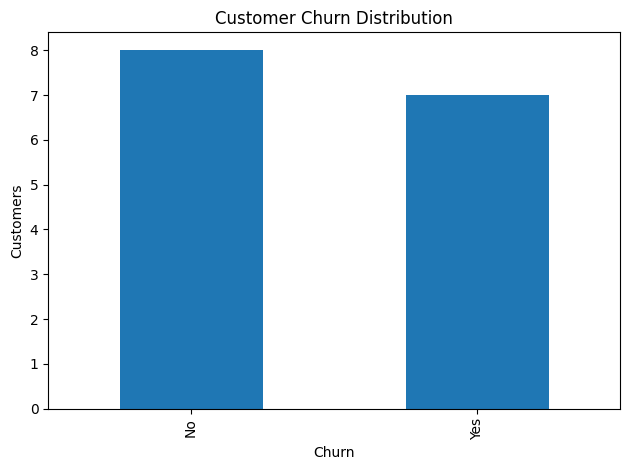

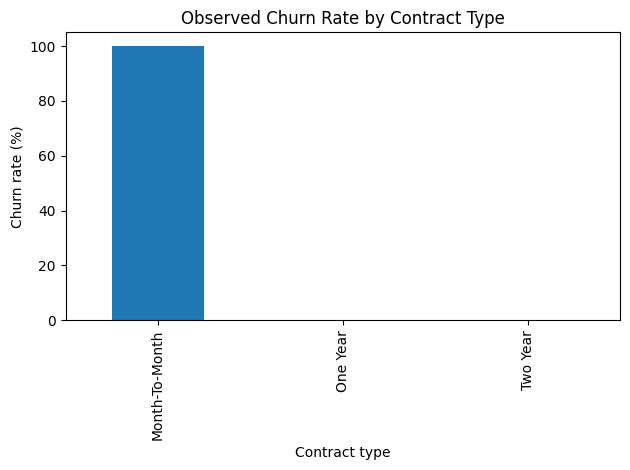

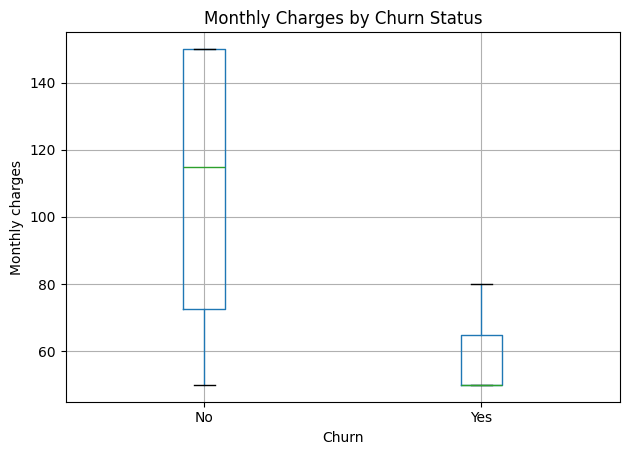

In [7]:
clean["Churn"].value_counts().reindex(["No", "Yes"]).plot(kind="bar", title="Customer Churn Distribution")
plt.xlabel("Churn"); plt.ylabel("Customers"); plt.tight_layout(); plt.show()

(clean.groupby("ContractType")["Churn"].apply(lambda s: (s == "Yes").mean() * 100)
 .sort_values(ascending=False).plot(kind="bar", title="Observed Churn Rate by Contract Type"))
plt.xlabel("Contract type"); plt.ylabel("Churn rate (%)"); plt.tight_layout(); plt.show()

clean.boxplot(column="MonthlyCharges", by="Churn")
plt.title("Monthly Charges by Churn Status"); plt.suptitle("")
plt.xlabel("Churn"); plt.ylabel("Monthly charges"); plt.tight_layout(); plt.show()

## 8. Export final dataset and checklist

In [8]:
clean.to_csv("cleaned_customer_churn.csv", index=False)
print("Exported cleaned_customer_churn.csv")
print(f"Rows: {len(clean)} | columns: {len(clean.columns)}")
print(f"Missing cells remaining: {int(clean.isna().sum().sum())}")
print(f"Validation checks passed: {int(validation['passed'].sum())}/{len(validation)}")

Exported cleaned_customer_churn.csv
Rows: 15 | columns: 11
Missing cells remaining: 0
Validation checks passed: 9/9
